**CNNs na prática: usando modelos pré-treinados do Hugging Face**

<table align="left">
  <td>
    <a href="https://colab.research.google.com/github/flavio-mota/si-rna-ag-2025/blob/main/CNN/Aula_8b_CNNs_Aplicacoes_HuggingFace.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>
  </td>
</table>

### Por que este notebook?

No dia a dia, raramente treinamos uma CNN do zero: treinar redes profundas exige milhões de imagens, GPUs potentes e dias de processamento.

Na prática, o caminho mais comum é:

1. **Procurar um modelo pré-treinado** que já resolve um problema parecido com o nosso;
2. **Usá-lo diretamente** (inferência), se a tarefa for a mesma para a qual ele foi treinado;
3. **Adaptá-lo** ao nosso problema com pouco treino (*transfer learning* / *fine-tuning*), quando a tarefa é diferente.

O **Hugging Face Hub** (https://huggingface.co/models) é hoje o principal repositório público desses modelos. Lá encontramos milhares de redes prontas para classificação, detecção de objetos, segmentação e muito mais, todas com poucas linhas de código.

**O que vamos fazer nesta aula:**

| # | Aplicação | Modelo (Hugging Face) | Treino necessário? |
|---|-----------|----------------------|--------------------|
| 1 | Classificar imagens em 1.000 categorias | `microsoft/resnet-50`, `facebook/convnext-tiny-224`, `google/mobilenet_v2_1.0_224` | Nenhum |
| 2 | Detectar e localizar objetos | `facebook/detr-resnet-50` | Nenhum |
| 3 | Segmentar a imagem pixel a pixel | `google/deeplabv3_mobilenet_v2_1.0_513` | Nenhum |
| 4 | Usar a CNN como extratora de características (busca por imagens parecidas) | `timm/resnet50.a1_in1k` | Nenhum |
| 5 | Diagnosticar doenças em folhas de feijão | `timm/resnet18.a1_in1k` + dataset `beans` | Poucos minutos |
| 6 | Publicar um mini-aplicativo web com o modelo | Gradio | Nenhum |

### Configurando o ambiente

Vamos usar três bibliotecas do ecossistema Hugging Face:

- **`transformers`**: apesar do nome, traz também diversas CNNs (ResNet, ConvNeXt, MobileNet, DeepLab...) e a função `pipeline`, que esconde todo o pré-processamento;
- **`timm`** (*PyTorch Image Models*): a maior coleção de CNNs pré-treinadas, com pesos hospedados no Hugging Face Hub;
- **`datasets`**: para baixar conjuntos de dados do Hub com uma linha.

Diferente do notebook anterior (TensorFlow/Keras), aqui o "motor" é o **PyTorch**, que é o framework usado pela grande maioria dos modelos do Hub. Os conceitos (convoluções, pooling, camadas densas) são exatamente os mesmos.

In [1]:
!pip install -q transformers datasets timm gradio

In [2]:
import time
import requests
from io import BytesIO

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

import torch
import timm
from transformers import pipeline

plt.rc('font', size=12)
plt.rc('axes', labelsize=12, titlesize=12)

Vamos verificar se há uma GPU disponível. **Inferência** (usar o modelo pronto) roda bem até em CPU; a GPU faz diferença principalmente na seção de *fine-tuning*.

In [3]:
import sys

IS_COLAB = "google.colab" in sys.modules
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Dispositivo:", device)

if device == "cpu":
    print("Nenhuma GPU foi detectada. A inferência funciona, mas o fine-tuning ficará mais lento.")
    if IS_COLAB:
        print("Acesse Runtime > Alterar tipo de ambiente de execução e selecione uma GPU (T4).")

Dispositivo: cuda


Uma função auxiliar para carregar imagens da internet. Usaremos algumas fotos do conjunto **COCO** (um dataset público de imagens do cotidiano).

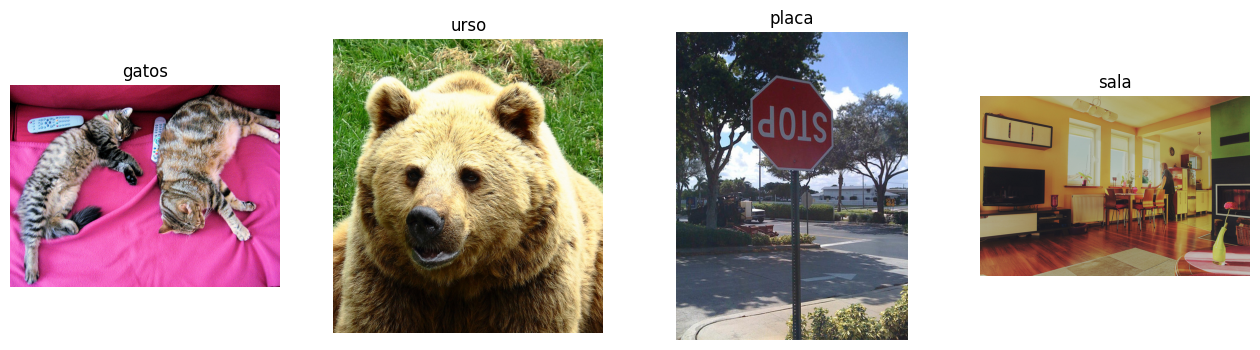

In [4]:
def carregar_imagem(url):
    """Baixa uma imagem de uma URL e devolve um objeto PIL em RGB."""
    resposta = requests.get(url, headers={"User-Agent": "Mozilla/5.0"}, timeout=30)
    resposta.raise_for_status()
    return Image.open(BytesIO(resposta.content)).convert("RGB")

urls = {
    "gatos":     "http://images.cocodataset.org/val2017/000000039769.jpg",
    "urso":      "http://images.cocodataset.org/val2017/000000000285.jpg",
    "placa":     "http://images.cocodataset.org/val2017/000000000724.jpg",
    "sala":      "http://images.cocodataset.org/val2017/000000000139.jpg",
}
imagens = {nome: carregar_imagem(url) for nome, url in urls.items()}

fig, axes = plt.subplots(1, len(imagens), figsize=(16, 4))
for ax, (nome, img) in zip(axes, imagens.items()):
    ax.imshow(img)
    ax.set_title(nome)
    ax.axis("off")
plt.show()

# 1. Classificação de imagens em 3 linhas de código

A função `pipeline` do `transformers` faz tudo o que fizemos manualmente com a ResNet50 no notebook anterior:

- baixa os pesos do modelo do Hugging Face Hub (só na primeira vez; depois fica em cache);
- redimensiona e normaliza a imagem do jeito que o modelo espera;
- executa a rede e converte as saídas (logits) em rótulos legíveis com probabilidades.

O modelo `microsoft/resnet-50` é a mesma arquitetura ResNet50 da aula passada, treinada no **ImageNet** (1.000 classes).

In [5]:
classificador = pipeline("image-classification",
                         model="microsoft/resnet-50",
                         device=0 if device == "cuda" else -1)

for nome, img in imagens.items():
    print(f"Imagem: {nome}")
    for pred in classificador(img, top_k=3):
        print(f"   {pred['label'][:40]:40s} {pred['score']:.2%}")

config.json:   0%|          | 0.00/69.6k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/266 [00:00<?, ?B/s]

Imagem: gatos
   tiger cat                                94.09%
   tabby, tabby cat                         3.49%
   remote control, remote                   0.17%
Imagem: urso
   brown bear, bruin, Ursus arctos          99.99%
   sloth bear, Melursus ursinus, Ursus ursi 0.00%
   crane                                    0.00%
Imagem: placa
   street sign                              99.26%
   traffic light, traffic signal, stoplight 0.54%
   pole                                     0.02%
Imagem: sala
   grand piano, grand                       18.62%
   window shade                             15.96%
   sliding door                             7.39%


Repare que **não escrevemos nenhuma camada**, não definimos otimizador e não treinamos nada. Ainda assim, o modelo reconhece gatos, ursos e placas de trânsito com boa confiança.

> 💡 Se a imagem contém um objeto que **não existe** entre as 1.000 classes do ImageNet (por exemplo, a sala de estar), o modelo vai "chutar" a classe mais parecida que conhece. Um classificador só sabe responder com as classes que viu no treino!

### Comparando modelos: precisão × tamanho × velocidade

No Hub existem várias CNNs para a mesma tarefa. A escolha do modelo é uma decisão de engenharia:

- **ResNet-50** (2015): o "clássico", ~25 milhões de parâmetros;
- **ConvNeXt-Tiny** (2022): uma CNN moderna, redesenhada com ideias dos Transformers, com acurácia maior;
- **MobileNetV2** (2018): projetada para celulares e dispositivos embarcados; muito menor e mais rápida.

Vamos comparar as três na mesma imagem, medindo número de parâmetros e tempo de inferência.

In [6]:
modelos = {
    "ResNet-50":     "microsoft/resnet-50",
    "ConvNeXt-Tiny": "facebook/convnext-tiny-224",
    "MobileNetV2":   "google/mobilenet_v2_1.0_224",
}

img_teste = imagens["urso"]
resultados = []

for nome, repo in modelos.items():
    clf = pipeline("image-classification", model=repo, device=0 if device == "cuda" else -1)
    clf(img_teste)  # "aquecimento": a primeira chamada costuma ser mais lenta

    inicio = time.perf_counter()
    for _ in range(10):
        pred = clf(img_teste, top_k=1)[0]
    tempo_ms = (time.perf_counter() - inicio) / 10 * 1000

    n_params = sum(p.numel() for p in clf.model.parameters()) / 1e6
    resultados.append((nome, n_params, tempo_ms, pred["label"], pred["score"]))

print(f"{'Modelo':15s} {'Parâmetros':>12s} {'Tempo':>10s}   Predição")
for nome, n_params, tempo_ms, label, score in resultados:
    print(f"{nome:15s} {n_params:10.1f} M {tempo_ms:8.1f} ms   {label[:30]} ({score:.1%})")

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


config.json:   0%|          | 0.00/69.6k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  114MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

...

model.safetensors: reconstructing file:   0%|          |  0.00B / 14.2MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/314 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/406 [00:00<?, ?B/s]

Modelo            Parâmetros      Tempo   Predição
ResNet-50             25.6 M     39.8 ms   brown bear, bruin, Ursus arcto (100.0%)
ConvNeXt-Tiny         28.6 M     37.9 ms   brown bear, bruin, Ursus arcto (91.2%)
MobileNetV2            3.5 M     24.3 ms   brown bear, bruin, Ursus arcto (95.5%)


**Discussão:** qual modelo você escolheria para:

- um aplicativo de celular que roda offline?
- um sistema em servidor que precisa da maior precisão possível?
- uma câmera embarcada em um Raspberry Pi monitorando uma linha de produção?

# 2. Detecção de objetos: *o quê* e *onde*

A classificação dá **um rótulo para a imagem inteira**. Em muitas aplicações reais (contagem de veículos, segurança do trabalho, inspeção industrial) precisamos saber **quais objetos existem e onde estão**.

O modelo `facebook/detr-resnet-50` usa uma **ResNet-50 como *backbone*** (a CNN que extrai as características da imagem) e, sobre ela, uma "cabeça" que prevê as caixas delimitadoras (*bounding boxes*). Ele foi treinado no COCO e reconhece 80 tipos de objetos (pessoas, carros, cadeiras, animais, alimentos...).

Esse é um padrão muito comum: a CNN pré-treinada vira um **componente** dentro de sistemas maiores.

config.json:   0%|          | 0.00/4.59k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  167MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/530 [00:00<?, ?it/s]

[transformers] DetrForObjectDetection LOAD REPORT from: facebook/detr-resnet-50
Key                                                            | Status     |  | 
---------------------------------------------------------------+------------+--+-
model.backbone.model.layer1.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 
model.backbone.model.layer2.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 
model.backbone.model.layer4.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 
model.backbone.model.layer3.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


preprocessor_config.json:   0%|          | 0.00/290 [00:00<?, ?B/s]

sala: 17 objetos detectados


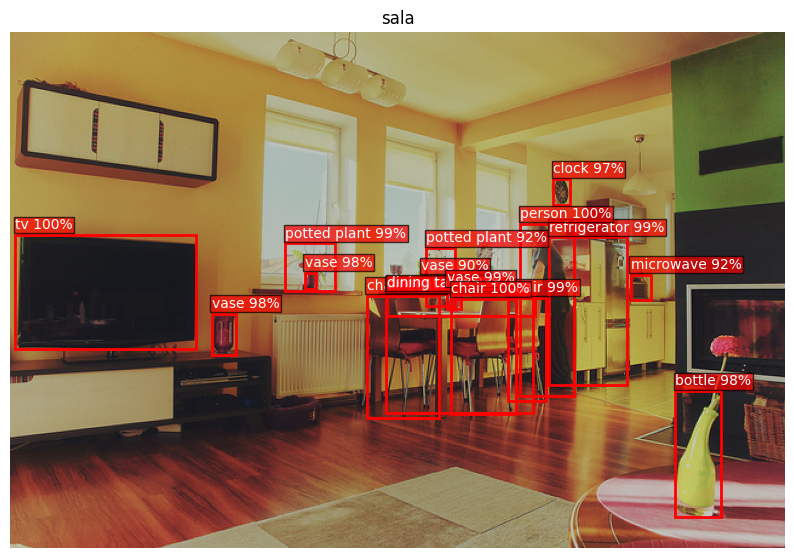

gatos: 5 objetos detectados


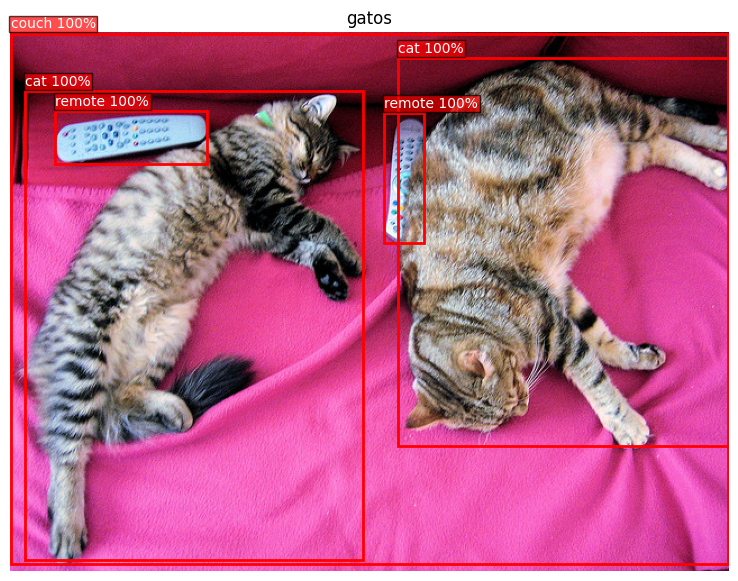

In [7]:
detector = pipeline("object-detection",
                    model="facebook/detr-resnet-50",
                    device=0 if device == "cuda" else -1)

def mostrar_deteccoes(img, deteccoes, titulo=""):
    fig, ax = plt.subplots(figsize=(10, 7))
    ax.imshow(img)
    for d in deteccoes:
        caixa = d["box"]
        x, y = caixa["xmin"], caixa["ymin"]
        w, h = caixa["xmax"] - x, caixa["ymax"] - y
        ax.add_patch(patches.Rectangle((x, y), w, h, fill=False, color="red", linewidth=2))
        ax.text(x, y - 5, f"{d['label']} {d['score']:.0%}", color="white", fontsize=10,
                bbox=dict(facecolor="red", alpha=0.7, pad=1))
    ax.set_title(titulo)
    ax.axis("off")
    plt.show()

for nome in ["sala", "gatos"]:
    deteccoes = detector(imagens[nome], threshold=0.9)
    print(f"{nome}: {len(deteccoes)} objetos detectados")
    mostrar_deteccoes(imagens[nome], deteccoes, titulo=nome)

Experimente alterar o `threshold` (limiar de confiança). Com valores menores, o modelo mostra mais objetos, mas também mais erros. Esse é o clássico compromisso entre **precisão** e **revocação** (*precision* × *recall*).

Com o resultado em mãos, aplicações práticas ficam simples. Por exemplo, **contar objetos**:

In [8]:
from collections import Counter

deteccoes = detector(imagens["sala"], threshold=0.9)
contagem = Counter(d["label"] for d in deteccoes)
for objeto, qtd in contagem.most_common():
    print(f"{objeto:15s} {qtd}")

vase            4
chair           3
potted plant    2
dining table    2
microwave       1
tv              1
bottle          1
refrigerator    1
clock           1
person          1


# 3. Segmentação semântica: classificando cada pixel

Na segmentação, a rede atribui uma classe **a cada pixel** da imagem. É a técnica usada em carros autônomos (separar pista, calçada, pedestres), em imagens médicas (delimitar tumores) e em sensoriamento remoto (mapear plantações, rios, áreas urbanas).

O modelo `google/deeplabv3_mobilenet_v2_1.0_513` combina:

- uma **MobileNetV2** como backbone (leve, pensada para dispositivos móveis);
- o módulo **DeepLabV3**, que usa *convoluções dilatadas* (*atrous convolutions*) para enxergar contexto em várias escalas sem perder resolução.

Ele foi treinado no PASCAL VOC (21 classes: pessoa, gato, cachorro, carro, sofá, TV...).

config.json:   0%|          | 0.00/1.38k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 10.4MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/332 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 10.3MB            

model.safetensors: downloading bytes:           |  0.00B            

preprocessor_config.json:   0%|          | 0.00/406 [00:00<?, ?B/s]

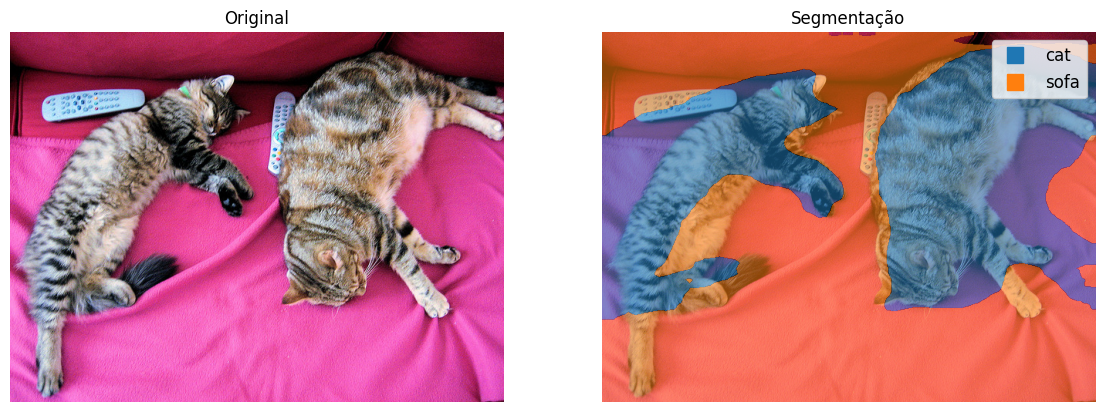

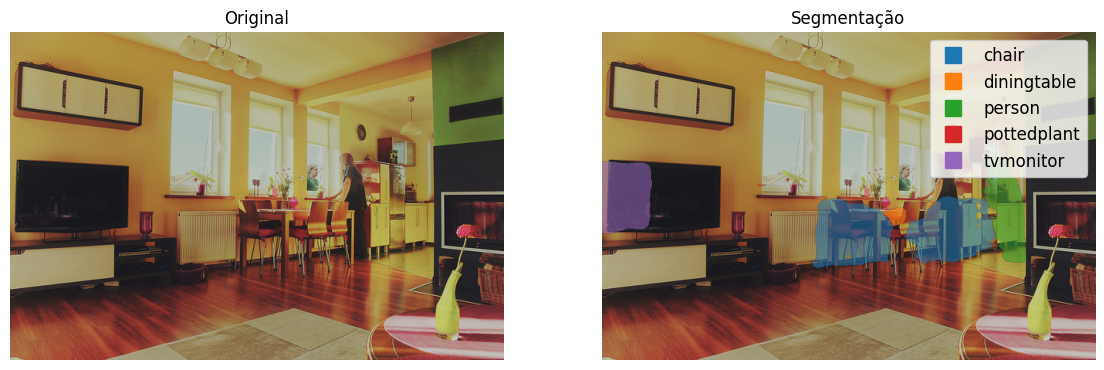

In [9]:
segmentador = pipeline("image-segmentation",
                       model="google/deeplabv3_mobilenet_v2_1.0_513",
                       device=0 if device == "cuda" else -1)

def mostrar_segmentacao(img, segmentos):
    segmentos = [s for s in segmentos if s["label"] != "background"]
    cores = plt.cm.tab10(np.linspace(0, 1, 10))

    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    axes[0].imshow(img)
    axes[0].set_title("Original")
    axes[1].imshow(img)
    for i, s in enumerate(segmentos):
        mascara = np.array(s["mask"]) > 0
        camada = np.zeros((*mascara.shape, 4))
        camada[mascara] = [*cores[i % 10][:3], 0.55]
        axes[1].imshow(camada)
        axes[1].plot([], [], "s", color=cores[i % 10], markersize=12, label=s["label"])
    axes[1].legend(loc="upper right")
    axes[1].set_title("Segmentação")
    for ax in axes:
        ax.axis("off")
    plt.show()

for nome in ["gatos", "sala"]:
    mostrar_segmentacao(imagens[nome], segmentador(imagens[nome]))

Com a máscara de cada classe, podemos calcular, por exemplo, **qual porcentagem da imagem é ocupada por cada objeto**, algo útil para estimar área plantada em fotos de drone ou área de uma lesão em uma imagem médica:

In [10]:
segmentos = segmentador(imagens["gatos"])
total_pixels = imagens["gatos"].size[0] * imagens["gatos"].size[1]
for s in segmentos:
    area = (np.array(s["mask"]) > 0).sum() / total_pixels
    print(f"{s['label']:12s} {area:6.1%} da imagem")

background     0.9% da imagem
cat           42.1% da imagem
sofa          56.9% da imagem


# 4. A CNN como extratora de características

Lembra que, na nossa CNN do notebook anterior, as camadas convolucionais extraíam características e as camadas densas no final faziam a classificação?

Se **removermos a última camada** de uma CNN pré-treinada, ela deixa de devolver "gato 95%" e passa a devolver um **vetor numérico** (*embedding*) que resume o conteúdo visual da imagem. Imagens parecidas geram vetores próximos.

Isso permite construir, **sem nenhum treino**:

- busca por imagens similares (como o "pesquisar por imagem" do Google);
- detecção de produtos duplicados em um e-commerce;
- agrupamento (*clustering*) de fotos.

Vamos usar a biblioteca `timm`. O prefixo `timm/` indica que os pesos estão no Hugging Face Hub (https://huggingface.co/timm). O argumento `num_classes=0` remove a camada de classificação.

In [11]:
extrator = timm.create_model("resnet50.a1_in1k", pretrained=True, num_classes=0)
extrator = extrator.eval().to(device)

# o timm informa o pré-processamento correto para cada modelo
config_dados = timm.data.resolve_model_data_config(extrator)
transform_extrator = timm.data.create_transform(**config_dados, is_training=False)
print(config_dados)

with torch.no_grad():
    x = transform_extrator(imagens["gatos"]).unsqueeze(0).to(device)
    embedding = extrator(x)
print("Formato do embedding:", embedding.shape)

model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

{'input_size': (3, 224, 224), 'interpolation': 'bicubic', 'mean': (0.485, 0.456, 0.406), 'std': (0.229, 0.224, 0.225), 'crop_pct': 0.95, 'crop_mode': 'center'}
Formato do embedding: torch.Size([1, 2048])


Cada imagem virou um vetor de **2.048 números**. Para testar se esses vetores fazem sentido, vamos usar o dataset **beans** do Hugging Face: fotos de folhas de feijão tiradas com celular em plantações de Uganda, divididas em 3 classes:

- `angular_leaf_spot` (mancha angular);
- `bean_rust` (ferrugem);
- `healthy` (saudável).

Vamos extrair os embeddings das imagens de teste e projetá-los em 2D. Atenção: **a ResNet-50 nunca foi treinada para reconhecer doenças em feijão**.

README.md:   0%|          | 0.00/4.95k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  144MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 18.5MB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/1034 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/133 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/128 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['image_file_path', 'image', 'labels'],
        num_rows: 1034
    })
    validation: Dataset({
        features: ['image_file_path', 'image', 'labels'],
        num_rows: 133
    })
    test: Dataset({
        features: ['image_file_path', 'image', 'labels'],
        num_rows: 128
    })
})
Classes: ['angular_leaf_spot', 'bean_rust', 'healthy']


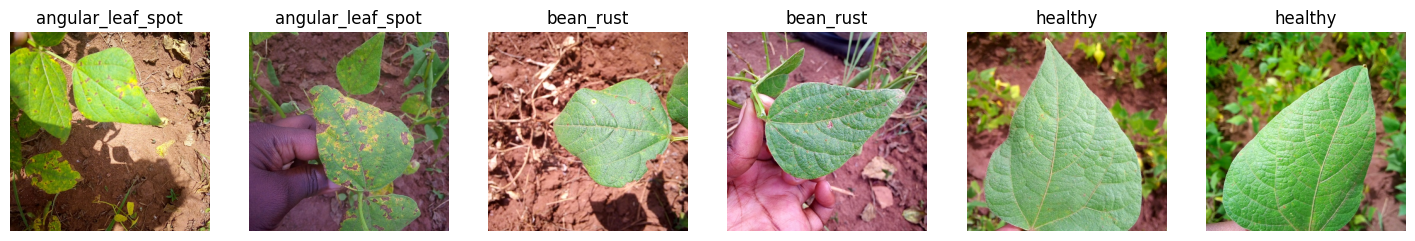

In [12]:
from datasets import load_dataset

beans = load_dataset("AI-Lab-Makerere/beans")
nomes_classes = beans["train"].features["labels"].names
print(beans)
print("Classes:", nomes_classes)

fig, axes = plt.subplots(1, 6, figsize=(18, 3.5))
for ax, i in zip(axes, [0, 1, 400, 401, 800, 801]):
    exemplo = beans["train"][i]
    ax.imshow(exemplo["image"])
    ax.set_title(nomes_classes[exemplo["labels"]])
    ax.axis("off")
plt.show()

In [13]:
@torch.no_grad()
def extrair_embeddings(modelo, transform, imagens_pil, batch_size=32):
    vetores = []
    for i in range(0, len(imagens_pil), batch_size):
        lote = torch.stack([transform(img.convert("RGB")) for img in imagens_pil[i:i + batch_size]])
        vetores.append(modelo(lote.to(device)).cpu())
    return torch.cat(vetores).numpy()

imgs_teste = list(beans["test"]["image"])
rotulos_teste = np.array(list(beans["test"]["labels"]))
emb_teste = extrair_embeddings(extrator, transform_extrator, imgs_teste)
print(emb_teste.shape)

(128, 2048)


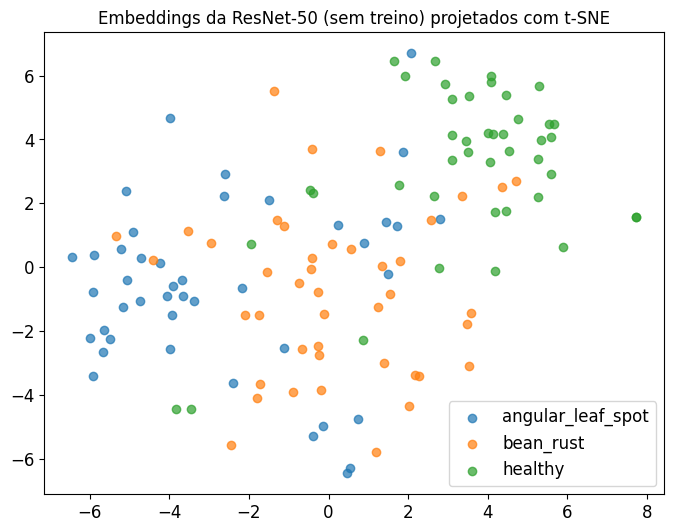

In [14]:
from sklearn.manifold import TSNE

emb_2d = TSNE(n_components=2, random_state=42, perplexity=30).fit_transform(emb_teste)

plt.figure(figsize=(8, 6))
for c, nome in enumerate(nomes_classes):
    idx = rotulos_teste == c
    plt.scatter(emb_2d[idx, 0], emb_2d[idx, 1], label=nome, alpha=0.7)
plt.legend()
plt.title("Embeddings da ResNet-50 (sem treino) projetados com t-SNE")
plt.show()

Mesmo sem treino, as classes já tendem a formar grupos. A rede aprendeu no ImageNet a reconhecer texturas, manchas e cores, e essas características servem para um problema completamente diferente!

Vamos usar os embeddings para uma **busca por imagens semelhantes**: dada uma folha, quais são as 5 mais parecidas no conjunto de teste? Usamos a **similaridade do cosseno** entre os vetores.

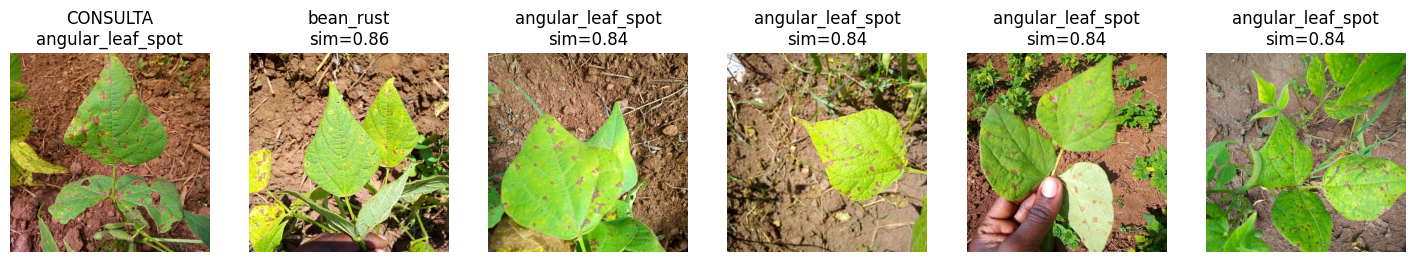

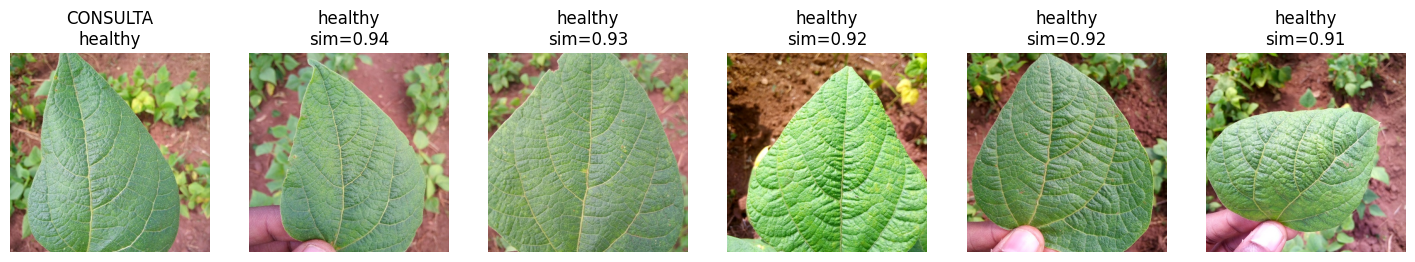

In [15]:
emb_norm = emb_teste / np.linalg.norm(emb_teste, axis=1, keepdims=True)

def buscar_similares(indice_consulta, k=5):
    similaridades = emb_norm @ emb_norm[indice_consulta]
    mais_proximos = np.argsort(-similaridades)[1:k + 1]  # [0] é a própria imagem

    fig, axes = plt.subplots(1, k + 1, figsize=(18, 3.5))
    axes[0].imshow(imgs_teste[indice_consulta])
    axes[0].set_title(f"CONSULTA\n{nomes_classes[rotulos_teste[indice_consulta]]}")
    for ax, j in zip(axes[1:], mais_proximos):
        ax.imshow(imgs_teste[j])
        ax.set_title(f"{nomes_classes[rotulos_teste[j]]}\nsim={similaridades[j]:.2f}")
    for ax in axes:
        ax.axis("off")
    plt.show()

buscar_similares(0)
buscar_similares(100)

Um teste simples de quanto essas características "genéricas" já resolvem: treinar uma **regressão logística** (um modelo linear, que treina em segundos) sobre os embeddings.

In [16]:
from sklearn.linear_model import LogisticRegression

emb_treino = extrair_embeddings(extrator, transform_extrator, list(beans["train"]["image"]))
rotulos_treino = np.array(list(beans["train"]["labels"]))

clf_linear = LogisticRegression(max_iter=2000).fit(emb_treino, rotulos_treino)
print(f"Acurácia no teste (embeddings + regressão logística): {clf_linear.score(emb_teste, rotulos_teste):.2%}")

Acurácia no teste (embeddings + regressão logística): 92.97%


# 5. Transfer learning: diagnosticando doenças em folhas de feijão

Agora vamos fazer o que se faz em projetos reais: **adaptar uma CNN pré-treinada a um problema novo**, com um dataset pequeno (~1.000 imagens de treino).

A estratégia tem duas etapas:

1. **Trocar a "cabeça"** da rede: a ResNet original termina com uma camada densa de 1.000 saídas (classes do ImageNet). Vamos substituí-la por uma com **3 saídas** (nossas classes);
2. **Treinar**: primeiro só a cabeça nova (as camadas convolucionais ficam congeladas), depois a rede inteira com taxa de aprendizado pequena (*fine-tuning*).

Para ver o valor do pré-treino, vamos comparar com **a mesma arquitetura treinada do zero**, como fizemos no notebook anterior.

Usaremos a `resnet18`, menor e mais rápida de treinar.

In [17]:
from torch.utils.data import DataLoader

NOME_MODELO = "resnet18.a1_in1k"

# o pré-processamento vem da configuração do modelo pré-treinado
modelo_ref = timm.create_model(NOME_MODELO, pretrained=True)
cfg = timm.data.resolve_model_data_config(modelo_ref)
transform_treino = timm.data.create_transform(**cfg, is_training=True)   # com data augmentation
transform_aval = timm.data.create_transform(**cfg, is_training=False)
del modelo_ref

def aplicar_transform(transform):
    def _f(lote):
        lote["pixel_values"] = [transform(img.convert("RGB")) for img in lote["image"]]
        return lote
    return _f

ds_treino = beans["train"].with_transform(aplicar_transform(transform_treino))
ds_val = beans["validation"].with_transform(aplicar_transform(transform_aval))
ds_teste = beans["test"].with_transform(aplicar_transform(transform_aval))

def collate(lote):
    return (torch.stack([ex["pixel_values"] for ex in lote]),
            torch.tensor([ex["labels"] for ex in lote]))

dl_treino = DataLoader(ds_treino, batch_size=32, shuffle=True, collate_fn=collate, num_workers=2)
dl_val = DataLoader(ds_val, batch_size=64, collate_fn=collate, num_workers=2)
dl_teste = DataLoader(ds_teste, batch_size=64, collate_fn=collate, num_workers=2)

model.safetensors: reconstructing file:   0%|          |  0.00B / 46.8MB            

model.safetensors: downloading bytes:           |  0.00B            

Funções de treino e avaliação. Esse é o "laço de treino" padrão do PyTorch, que no Keras fica escondido dentro do `model.fit()`.

In [18]:
@torch.no_grad()
def avaliar(modelo, loader):
    modelo.eval()
    acertos, total = 0, 0
    for x, y in loader:
        pred = modelo(x.to(device)).argmax(dim=1).cpu()
        acertos += (pred == y).sum().item()
        total += len(y)
    return acertos / total

def treinar(modelo, loader, epocas, lr):
    params = [p for p in modelo.parameters() if p.requires_grad]
    otimizador = torch.optim.AdamW(params, lr=lr)
    perda_fn = torch.nn.CrossEntropyLoss()
    historico = []
    for epoca in range(1, epocas + 1):
        modelo.train()
        inicio, perda_total = time.time(), 0.0
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            otimizador.zero_grad()
            perda = perda_fn(modelo(x), y)
            perda.backward()
            otimizador.step()
            perda_total += perda.item() * len(y)
        acc_val = avaliar(modelo, dl_val)
        historico.append(acc_val)
        print(f"Época {epoca:2d} | perda {perda_total / len(loader.dataset):.4f} "
              f"| acc. validação {acc_val:.2%} | {time.time() - inicio:.0f}s")
    return historico

### Etapa 1: treinando só a nova cabeça (camadas convolucionais congeladas)

`num_classes=3` faz o `timm` substituir automaticamente a camada final por uma nova, com 3 saídas e pesos aleatórios. Todo o resto vem pré-treinado do Hub.

In [19]:
torch.manual_seed(42)
modelo_ft = timm.create_model(NOME_MODELO, pretrained=True, num_classes=3).to(device)

# congela tudo, exceto a camada de classificação
for p in modelo_ft.parameters():
    p.requires_grad = False
for p in modelo_ft.get_classifier().parameters():
    p.requires_grad = True

treinaveis = sum(p.numel() for p in modelo_ft.parameters() if p.requires_grad)
total = sum(p.numel() for p in modelo_ft.parameters())
print(f"Parâmetros treináveis: {treinaveis:,} de {total:,} ({treinaveis / total:.3%})")

hist_cabeca = treinar(modelo_ft, dl_treino, epocas=3, lr=1e-3)

Parâmetros treináveis: 1,539 de 11,178,051 (0.014%)
Época  1 | perda 1.0577 | acc. validação 65.41% | 17s
Época  2 | perda 0.9087 | acc. validação 79.70% | 16s
Época  3 | perda 0.8159 | acc. validação 79.70% | 16s


### Etapa 2: *fine-tuning* da rede inteira

Agora "descongelamos" todas as camadas e treinamos com uma taxa de aprendizado **bem menor**, para ajustar finamente os filtros sem destruir o que a rede já sabia.

In [20]:
for p in modelo_ft.parameters():
    p.requires_grad = True

hist_ft = treinar(modelo_ft, dl_treino, epocas=5, lr=1e-4)

Época  1 | perda 0.7175 | acc. validação 80.45% | 14s
Época  2 | perda 0.5978 | acc. validação 81.95% | 10s
Época  3 | perda 0.4911 | acc. validação 87.97% | 9s
Época  4 | perda 0.4161 | acc. validação 87.97% | 9s
Época  5 | perda 0.3581 | acc. validação 88.72% | 9s


### Comparação: a mesma rede treinada do zero

Mesma arquitetura, mesmo número de épocas (8), mas com pesos aleatórios (`pretrained=False`).

In [21]:
torch.manual_seed(42)
modelo_zero = timm.create_model(NOME_MODELO, pretrained=False, num_classes=3).to(device)
hist_zero = treinar(modelo_zero, dl_treino, epocas=8, lr=1e-3)

Época  1 | perda 0.9776 | acc. validação 57.89% | 9s
Época  2 | perda 0.8798 | acc. validação 61.65% | 9s
Época  3 | perda 0.8800 | acc. validação 71.43% | 9s
Época  4 | perda 0.8888 | acc. validação 68.42% | 9s
Época  5 | perda 0.8676 | acc. validação 67.67% | 9s
Época  6 | perda 0.8641 | acc. validação 70.68% | 9s
Época  7 | perda 0.8002 | acc. validação 72.93% | 9s
Época  8 | perda 0.8096 | acc. validação 73.68% | 9s


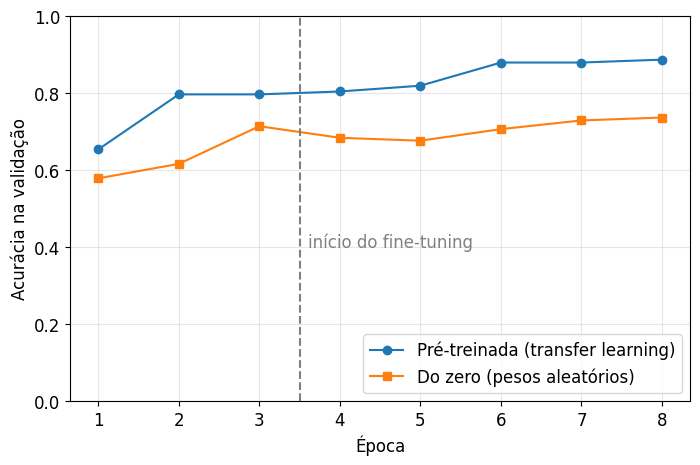

Acurácia no TESTE - pré-treinada: 89.84%
Acurácia no TESTE - do zero:      75.78%


In [22]:
plt.figure(figsize=(8, 5))
plt.plot(range(1, 9), hist_cabeca + hist_ft, "o-", label="Pré-treinada (transfer learning)")
plt.plot(range(1, 9), hist_zero, "s-", label="Do zero (pesos aleatórios)")
plt.axvline(3.5, color="gray", linestyle="--")
plt.text(3.6, 0.4, "início do fine-tuning", color="gray")
plt.xlabel("Época")
plt.ylabel("Acurácia na validação")
plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(f"Acurácia no TESTE - pré-treinada: {avaliar(modelo_ft, dl_teste):.2%}")
print(f"Acurácia no TESTE - do zero:      {avaliar(modelo_zero, dl_teste):.2%}")

Com poucos minutos de treino e só ~1.000 imagens, o modelo pré-treinado alcança uma acurácia muito superior à rede treinada do zero. **Essa é a principal razão pela qual o transfer learning domina as aplicações práticas de visão computacional.**

Vamos ver onde o modelo ainda erra com uma matriz de confusão:

                   precision    recall  f1-score   support

angular_leaf_spot       0.93      0.88      0.90        43
        bean_rust       0.82      0.93      0.87        43
          healthy       0.97      0.88      0.93        42

         accuracy                           0.90       128
        macro avg       0.91      0.90      0.90       128
     weighted avg       0.91      0.90      0.90       128



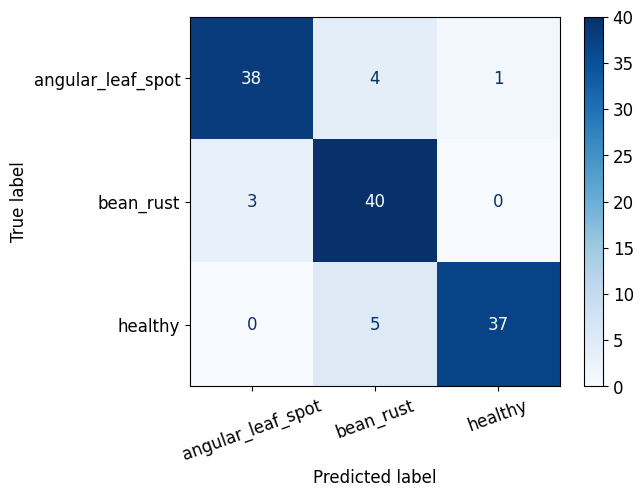

In [23]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

@torch.no_grad()
def prever_todos(modelo, loader):
    modelo.eval()
    y_true, y_pred = [], []
    for x, y in loader:
        y_pred.append(modelo(x.to(device)).argmax(dim=1).cpu())
        y_true.append(y)
    return torch.cat(y_true).numpy(), torch.cat(y_pred).numpy()

y_true, y_pred = prever_todos(modelo_ft, dl_teste)
print(classification_report(y_true, y_pred, target_names=nomes_classes))
ConfusionMatrixDisplay.from_predictions(y_true, y_pred, display_labels=nomes_classes,
                                        cmap="Blues", xticks_rotation=20)
plt.show()

### Usando o modelo treinado em uma imagem nova

Função para classificar qualquer foto de folha (por exemplo, enviada do celular):

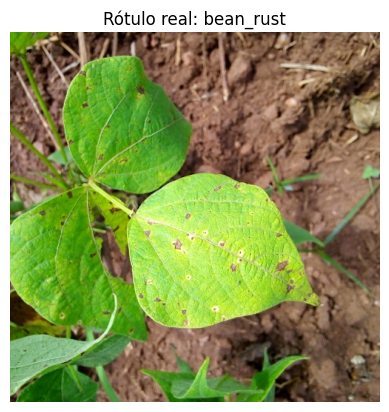

angular_leaf_spot    50.68%
bean_rust            48.22%
healthy              1.10%


In [24]:
@torch.no_grad()
def diagnosticar(img):
    modelo_ft.eval()
    x = transform_aval(img.convert("RGB")).unsqueeze(0).to(device)
    probs = modelo_ft(x).softmax(dim=1)[0].cpu()
    return {nomes_classes[i]: float(probs[i]) for i in range(len(nomes_classes))}

exemplo = beans["test"][50]
plt.imshow(exemplo["image"])
plt.axis("off")
plt.title(f"Rótulo real: {nomes_classes[exemplo['labels']]}")
plt.show()

for classe, p in sorted(diagnosticar(exemplo["image"]).items(), key=lambda t: -t[1]):
    print(f"{classe:20s} {p:.2%}")

> 💾 **Salvando e compartilhando:** o modelo pode ser salvo com `torch.save(modelo_ft.state_dict(), "beans_resnet18.pt")`. Com uma conta no Hugging Face, também é possível publicá-lo no Hub com `modelo_ft.push_to_hub(...)` (via `timm`), para que outras pessoas o usem exatamente como usamos os modelos desta aula.

# 6. Transformando o modelo em um aplicativo web

O **Gradio** cria uma interface web para o modelo com poucas linhas. No Colab, ao executar a célula abaixo, aparece uma interface onde você pode enviar uma foto e ver o diagnóstico. Com `share=True`, é gerado um link público temporário que pode ser aberto no celular.

É assim que muitos protótipos de IA são demonstrados (inclusive nos *Spaces* do Hugging Face).

In [ ]:
import gradio as gr

# salva algumas imagens de teste como exemplos clicáveis na interface
exemplos = []
for i in (0, 50, 100):
    caminho = f"exemplo_{i}.jpg"
    beans["test"][i]["image"].convert("RGB").save(caminho)
    exemplos.append([caminho])

app = gr.Interface(
    fn=diagnosticar,
    inputs=gr.Image(type="pil", label="Foto da folha de feijão"),
    outputs=gr.Label(num_top_classes=3, label="Diagnóstico"),
    title="Diagnóstico de doenças em folhas de feijão",
    description="ResNet-18 pré-treinada no ImageNet e ajustada no dataset beans.",
    examples=exemplos,
)
app.launch(share=True)

## Exercício prático: escolha um problema e um modelo do Hub

Neste exercício, você vai repetir o fluxo de trabalho de um projeto real de visão computacional.

**Parte A – Usando um modelo pronto**

1. Acesse https://huggingface.co/models e filtre por uma tarefa de visão (*Image Classification*, *Object Detection* ou *Image Segmentation*);
2. Escolha um modelo baseado em CNN (ResNet, ConvNeXt, EfficientNet, MobileNet, RegNet...) treinado para algo diferente do que vimos (ex.: alimentos, raças de cães, placas, defeitos industriais, raio-X);
3. Use a função `pipeline` para aplicá-lo a **três imagens suas** (use o botão de upload do Colab e `Image.open("arquivo.jpg")`);
4. Registre: as previsões, se fazem sentido e possíveis motivos para erros.

**Parte B – Transfer learning em outro dataset**

1. Escolha outro dataset de imagens do Hub (sugestões: `Bingsu/Cat_and_Dog`, `food101` com um subconjunto de classes, ou procure em https://huggingface.co/datasets filtrando por *Image Classification*);
2. Adapte o código da seção 5 (troque o dataset, os nomes das colunas e o `num_classes`);
3. Compare pelo menos **duas CNNs** do `timm` (ex.: `resnet18.a1_in1k` e `efficientnet_b0.ra_in1k`, ou `mobilenetv3_large_100.ra_in1k`) em termos de acurácia, número de parâmetros e tempo de treino.

**Perguntas para o relatório:**

- Qual a vantagem de congelar as camadas convolucionais nas primeiras épocas?
- Por que a taxa de aprendizado do *fine-tuning* é menor que a do treino da cabeça?
- Em que situação valeria a pena treinar uma CNN do zero em vez de usar um modelo pré-treinado?

In [ ]:
# Parte A - seu código aqui
# from google.colab import files
# enviados = files.upload()

# meu_modelo = pipeline("image-classification", model="...")  # coloque aqui o repositório escolhido

# img = Image.open("sua_imagem.jpg").convert("RGB")
# print(meu_modelo(img, top_k=3))